# First-innings cricket score prediction

Train a regression model that estimates a team's final first-innings total from its score at the end of an over. The model uses only match context and information available at that point. Matches are split by `match_id` so deliveries from the same match cannot appear in both training and evaluation.

## 1. Check data quality, create Parquet files, and prepare over snapshots

DuckDB checks the source CSVs and writes compressed Parquet copies under `datasets/processed/`. Dask aggregates deliveries to over-level records from Parquet; Polars calculates cumulative score and wicket features. The source CSV files are left unchanged.


In [ ]:
from pathlib import Path
import json
import warnings

import joblib
import mlflow
import duckdb
import dask.dataframe as dd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
display = lambda value: print(value.head() if hasattr(value, "head") else value)
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor, VotingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, confusion_matrix, mean_absolute_error, mean_squared_error, precision_score, r2_score, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd()
if not (ROOT / 'datasets' / 'matches.csv').exists():
    # Also works when Jupyter is launched from a subfolder.
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'datasets' / 'matches.csv').exists())
DATA_DIR = ROOT / 'datasets'
OUTPUT_DIR = ROOT / 'models'
OUTPUT_DIR.mkdir(exist_ok=True)
MLFLOW_TRACKING_URI = f"sqlite:///{(ROOT / 'mlflow.db').resolve().as_posix()}"
MLFLOW_ARTIFACT_DIR = ROOT / 'mlartifacts'
MLFLOW_ARTIFACT_DIR.mkdir(exist_ok=True)
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
MLFLOW_EXPERIMENT = 'Cricket first-innings score prediction'
if mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT) is None:
    mlflow.create_experiment(MLFLOW_EXPERIMENT, artifact_location=MLFLOW_ARTIFACT_DIR.resolve().as_uri())
mlflow.set_experiment(MLFLOW_EXPERIMENT)

# Read the source CSV files once with DuckDB. The original CSVs remain unchanged.
con = duckdb.connect(database=':memory:')
con.read_csv(str(DATA_DIR / 'matches.csv')).create_view('matches_csv', replace=True)
con.read_csv(str(DATA_DIR / 'deliveries.csv')).create_view('deliveries_csv', replace=True)

# Run basic integrity checks before writing or training from the data.
quality_report = con.execute("""
SELECT 'duplicate_match_ids' AS check_name, COUNT(*) AS issue_count
FROM (SELECT id FROM matches_csv GROUP BY id HAVING COUNT(*) > 1)
UNION ALL
SELECT 'orphan_deliveries', COUNT(*)
FROM deliveries_csv d LEFT JOIN matches_csv m ON m.id = d.match_id
WHERE m.id IS NULL
UNION ALL
SELECT 'null_critical_delivery_fields', COUNT(*)
FROM deliveries_csv
WHERE match_id IS NULL OR inning IS NULL OR over IS NULL OR ball IS NULL
   OR total_runs IS NULL OR is_wicket IS NULL
   OR batting_team IS NULL OR bowling_team IS NULL
UNION ALL
SELECT 'duplicate_delivery_keys', COUNT(*)
FROM (SELECT match_id, inning, over, ball FROM deliveries_csv
      GROUP BY match_id, inning, over, ball HAVING COUNT(*) > 1)
UNION ALL
SELECT 'run_component_mismatch', COUNT(*)
FROM deliveries_csv WHERE total_runs <> batsman_runs + extra_runs
UNION ALL
SELECT 'negative_runs', COUNT(*)
FROM deliveries_csv WHERE total_runs < 0 OR batsman_runs < 0 OR extra_runs < 0
UNION ALL
SELECT 'missing_match_teams_or_venue', COUNT(*)
FROM matches_csv WHERE team1 IS NULL OR team2 IS NULL OR venue IS NULL
""").df()
quality_report['status'] = np.where(quality_report['issue_count'].eq(0), 'PASS', 'CHECK')
quality_report_path = OUTPUT_DIR / 'data_quality_report.csv'
quality_report.to_csv(quality_report_path, index=False)
print('Data quality checks:')
print(quality_report.to_string(index=False))
if quality_report['issue_count'].sum() > 0:
    warnings.warn('One or more data quality checks found issues; review data_quality_report.csv before using the predictions.')

# Convert source CSVs to compressed Parquet, then use Parquet-backed views for SQL.
PARQUET_DIR = DATA_DIR / 'processed'
PARQUET_DIR.mkdir(exist_ok=True)
parquet_paths = {
    'matches': PARQUET_DIR / 'matches.parquet',
    'deliveries': PARQUET_DIR / 'deliveries.parquet',
}
def duckdb_sql_path(path):
    return path.resolve().as_posix().replace("'", "''")

for table_name, source_view in [('matches', 'matches_csv'), ('deliveries', 'deliveries_csv')]:
    parquet_path = parquet_paths[table_name]
    parquet_path.unlink(missing_ok=True)
    con.execute(f"COPY (SELECT * FROM {source_view}) TO '{duckdb_sql_path(parquet_path)}' (FORMAT PARQUET, COMPRESSION ZSTD)")
    con.execute(f"CREATE OR REPLACE VIEW {table_name} AS SELECT * FROM read_parquet('{duckdb_sql_path(parquet_path)}')")

match_count = con.execute('SELECT COUNT(*) FROM matches').fetchall()[0][0]
delivery_count = con.execute('SELECT COUNT(*) FROM deliveries').fetchall()[0][0]
print(f'Parquet-backed data ready: {match_count:,} matches; {delivery_count:,} deliveries')
print(f'Parquet files saved in {PARQUET_DIR}')
display(con.sql('SELECT * FROM matches LIMIT 3').df())
display(con.sql('SELECT * FROM deliveries LIMIT 3').df())

In [ ]:
# Dask reads the Parquet datasets in row-group partitions and aggregates delivery
# records to one row per match/innings/over. This is the large-table step that can
# scale when the Parquet dataset is split across many row groups or files.
match_path = PARQUET_DIR / 'matches.parquet'
delivery_path = PARQUET_DIR / 'deliveries.parquet'
match_parts = dd.read_parquet(str(match_path), split_row_groups=1)
delivery_parts = dd.read_parquet(str(delivery_path), split_row_groups=1)
print(f'Dask input partitions: {delivery_parts.npartitions:,} delivery partitions')

match_context = match_parts[['id', 'season', 'city', 'venue']].rename(columns={'id': 'match_id'})
match_context['season'] = match_context['season'].fillna('Unknown')
match_context['city'] = match_context['city'].fillna('Unknown').replace('NA', 'Unknown')
match_context['venue'] = match_context['venue'].fillna('Unknown')
first_deliveries = delivery_parts.loc[delivery_parts['inning'] == 1]
first_deliveries = first_deliveries.merge(match_context, on='match_id', how='inner')

over_keys = ['match_id', 'inning', 'batting_team', 'bowling_team', 'season', 'city', 'venue', 'over']
over_stats_dd = (first_deliveries.groupby(over_keys).agg({
    'total_runs': 'sum',
    'is_wicket': 'sum',
    'ball': 'count',
}).reset_index().rename(columns={
    'total_runs': 'runs_in_over',
    'is_wicket': 'wickets_in_over',
    'ball': 'balls_in_over',
}))
over_stats_pandas = over_stats_dd.compute()
print(f'Dask produced {len(over_stats_pandas):,} over-level records.')

# Polars turns the reduced over table into cumulative in-innings snapshots.
group_cols = ['match_id', 'inning', 'batting_team', 'bowling_team', 'season', 'city', 'venue']
over_stats = pl.from_pandas(over_stats_pandas).with_columns(
    pl.col('season').cast(pl.String).str.extract(r'(\d{4})', 1).cast(pl.Int64, strict=False).alias('season')
).sort(group_cols + ['over'])
over_stats = over_stats.with_columns([
    pl.col('runs_in_over').cum_sum().over(group_cols).alias('current_score'),
    pl.col('wickets_in_over').cum_sum().over(group_cols).clip(upper_bound=10).alias('wickets_lost'),
    pl.col('balls_in_over').cum_sum().over(group_cols).alias('balls_faced'),
    (pl.col('over') + 1).alias('overs_elapsed'),
])
over_stats = over_stats.with_columns(
    pl.col('current_score').max().over(group_cols).alias('final_score')
)
data = (over_stats.filter((pl.col('overs_elapsed') < 20) & (pl.col('final_score') > 0))
    .with_columns((pl.col('current_score') / pl.col('overs_elapsed')).alias('run_rate'))
    .to_pandas())

group_cols = ['match_id', 'inning', 'batting_team', 'bowling_team', 'season', 'city', 'venue']
numeric_features = ['season', 'overs_elapsed', 'current_score', 'wickets_lost', 'balls_faced', 'run_rate']
categorical_features = ['batting_team', 'bowling_team', 'city', 'venue']
feature_columns = numeric_features + categorical_features
data[categorical_features] = data[categorical_features].replace('NA', np.nan).fillna('Unknown').astype(str)
data = data.dropna(subset=['final_score', 'current_score'])
print(f'Training samples: {len(data):,}; first-innings innings: {data.match_id.nunique():,}')
display(data[feature_columns + ['final_score']].head())

## 2. Explore the data

These charts show the innings score distribution, how scores build across overs, and the relationship between a current score and the eventual total.

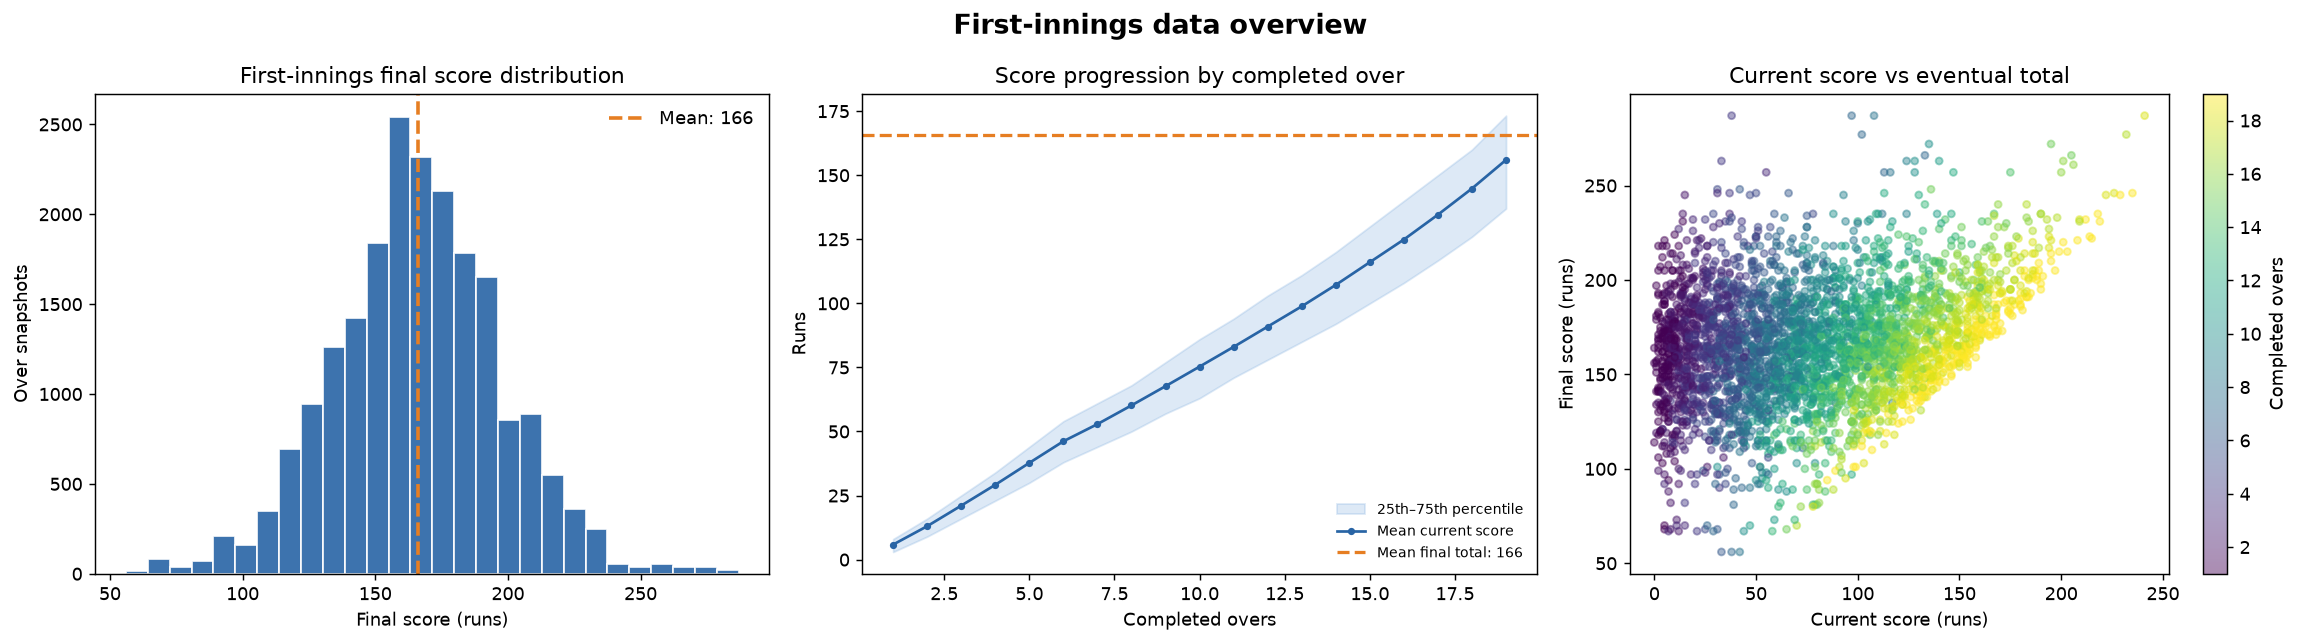

In [3]:
# Data overview: target distribution, scoring progression, and current-vs-final score.
PLOT_DIR = OUTPUT_DIR / 'plots'
PLOT_DIR.mkdir(exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].hist(data['final_score'], bins=28, color='#2864a5', edgecolor='white', alpha=0.9)
axes[0].axvline(data['final_score'].mean(), color='#e67e22', linestyle='--', linewidth=2, label=f"Mean: {data['final_score'].mean():.0f}")
axes[0].set(title='First-innings final score distribution', xlabel='Final score (runs)', ylabel='Over snapshots')
axes[0].legend(frameon=False)

progress = (data.groupby('overs_elapsed')['current_score']
    .agg(mean='mean', p25=lambda values: values.quantile(0.25), p75=lambda values: values.quantile(0.75))
    .reset_index())
mean_total = data.drop_duplicates('match_id')['final_score'].mean()
axes[1].fill_between(progress['overs_elapsed'], progress['p25'], progress['p75'], color='#78a9dc', alpha=0.25, label='25th–75th percentile')
axes[1].plot(progress['overs_elapsed'], progress['mean'], color='#2864a5', marker='o', markersize=3, label='Mean current score')
axes[1].axhline(mean_total, color='#e67e22', linestyle='--', linewidth=1.8, label=f'Mean final total: {mean_total:.0f}')
axes[1].set(title='Score progression by completed over', xlabel='Completed overs', ylabel='Runs')
axes[1].legend(frameon=False, fontsize=8)

scatter_sample = data.sample(n=min(3500, len(data)), random_state=42)
points = axes[2].scatter(scatter_sample['current_score'], scatter_sample['final_score'], c=scatter_sample['overs_elapsed'], cmap='viridis', alpha=0.45, s=15)
axes[2].set(title='Current score vs eventual total', xlabel='Current score (runs)', ylabel='Final score (runs)')
fig.colorbar(points, ax=axes[2], label='Completed overs')
fig.suptitle('First-innings data overview', fontsize=15, fontweight='bold')
fig.tight_layout()
fig.savefig(PLOT_DIR / 'data_overview.png', dpi=160, bbox_inches='tight')
plt.show()

## 3. Split by match and train

A grouped holdout gives a more realistic estimate than randomly splitting over snapshots, because all snapshots from a match stay together.

In [ ]:
X = data[feature_columns]
y = data['final_score'].astype(float)
groups = data['match_id']
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

numeric_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
categorical_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=2))])
preprocessor = ColumnTransformer([('numeric', numeric_pipe, numeric_features), ('categorical', categorical_pipe, categorical_features)])

model = Pipeline([('preprocess', preprocessor), ('regressor', RandomForestRegressor(n_estimators=25, min_samples_leaf=5, max_features=0.5, n_jobs=1, random_state=42))])
model.fit(X_train, y_train)
predictions = np.clip(model.predict(X_test), 0, None)

# A separate classifier targets 180+ totals once at least 16 overs are complete.
late_train = data.loc[X_train.index].loc[lambda frame: frame['overs_elapsed'] >= 16]
late_test = data.loc[X_test.index].loc[lambda frame: frame['overs_elapsed'] >= 16]
late_classifier = Pipeline([('preprocess', clone(preprocessor)), ('classifier', LogisticRegression(max_iter=250, C=0.5))])
late_classifier.fit(late_train[feature_columns], (late_train['final_score'] >= 180).astype(int))
late_predictions = late_classifier.predict(late_test[feature_columns])
late_actual = (late_test['final_score'] >= 180).astype(int)
late_accuracy = accuracy_score(late_actual, late_predictions)
late_precision = precision_score(late_actual, late_predictions, zero_division=0)
late_recall = recall_score(late_actual, late_predictions, zero_division=0)
metrics = {'MAE': mean_absolute_error(y_test, predictions), 'RMSE': mean_squared_error(y_test, predictions) ** 0.5, 'R2': r2_score(y_test, predictions), 'train_matches': int(groups.iloc[train_idx].nunique()), 'test_matches': int(groups.iloc[test_idx].nunique()), 'test_samples': int(len(test_idx)), 'late_classifier_overs_elapsed_min': 16, 'late_classifier_accuracy': late_accuracy, 'late_classifier_precision': late_precision, 'late_classifier_recall': late_recall, 'late_classifier_test_samples': int(len(late_test))}
high_score_threshold = 180
actual_high_score = y_test >= high_score_threshold
predicted_high_score = predictions >= high_score_threshold
metrics.update({'high_score_threshold_runs': high_score_threshold,
    'high_score_accuracy': accuracy_score(actual_high_score, predicted_high_score),
    'high_score_precision': precision_score(actual_high_score, predicted_high_score, zero_division=0)})
print(f"High-score definition: final score >= {high_score_threshold} runs")
print(f"High-score accuracy: {metrics['high_score_accuracy']:.1%}")
print(f"High-score precision (regression threshold): {metrics['high_score_precision']:.1%}")
print(f"Late classifier accuracy (16+ overs, 180+ runs): {late_accuracy:.1%}")
print(f"Late classifier precision: {late_precision:.1%}")
print(f"Late classifier recall: {late_recall:.1%}")
display(pd.DataFrame([metrics]).round(3))

## 4. Inspect model predictions and feature importance

Use the holdout plots to see prediction quality, how error changes by over, and which inputs the Random Forest relied on most. The late-classifier confusion matrix shows its 180+ decision on held-out innings states.

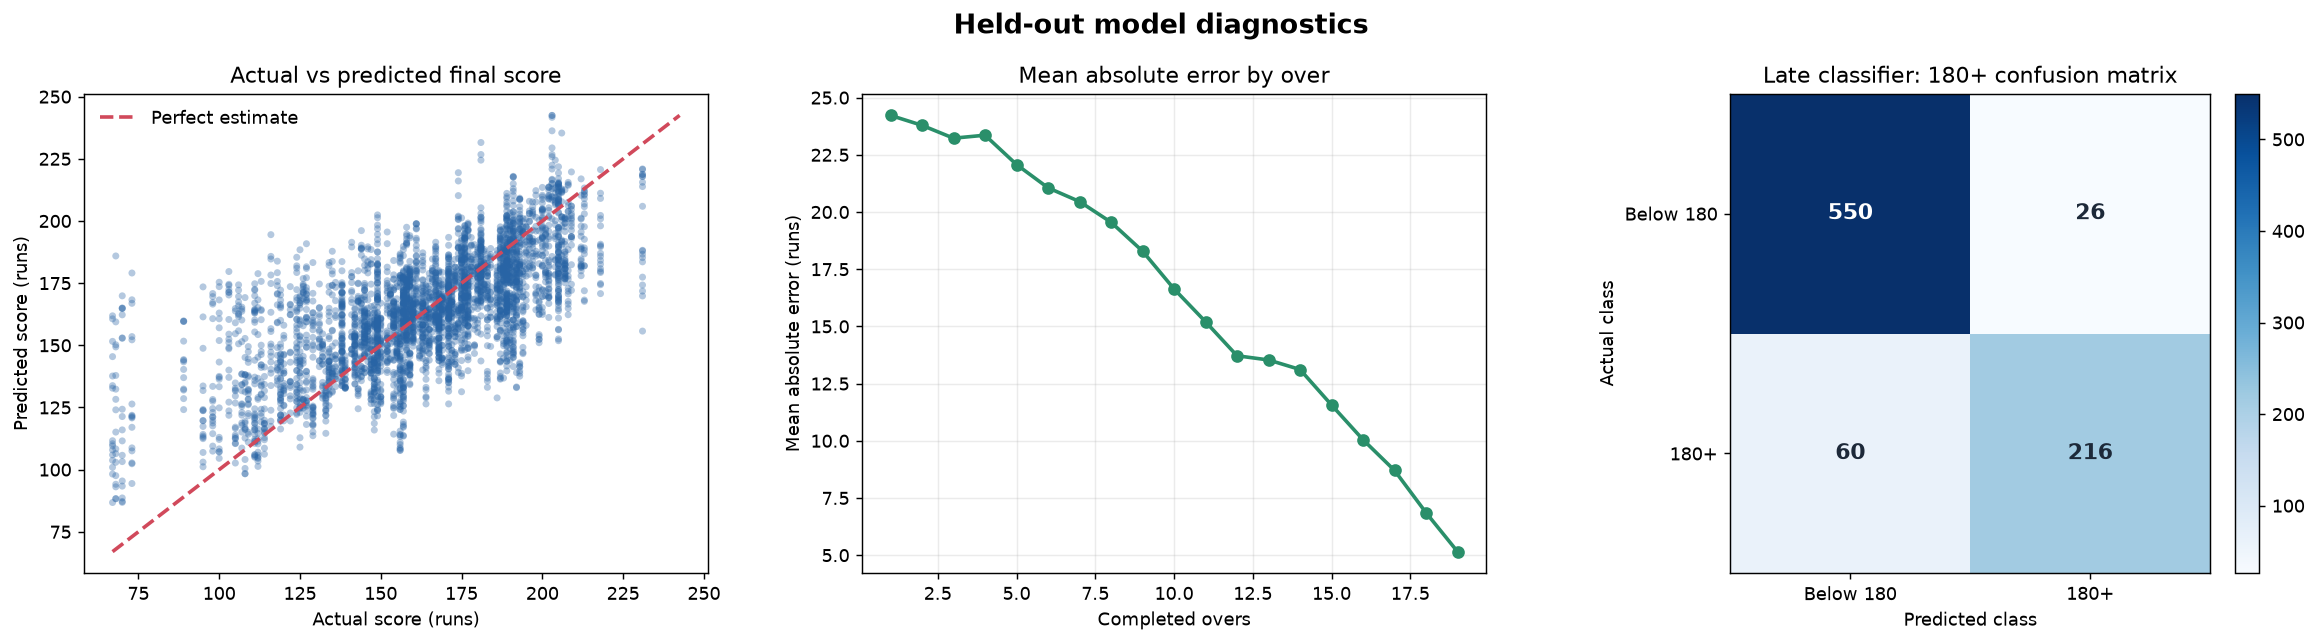

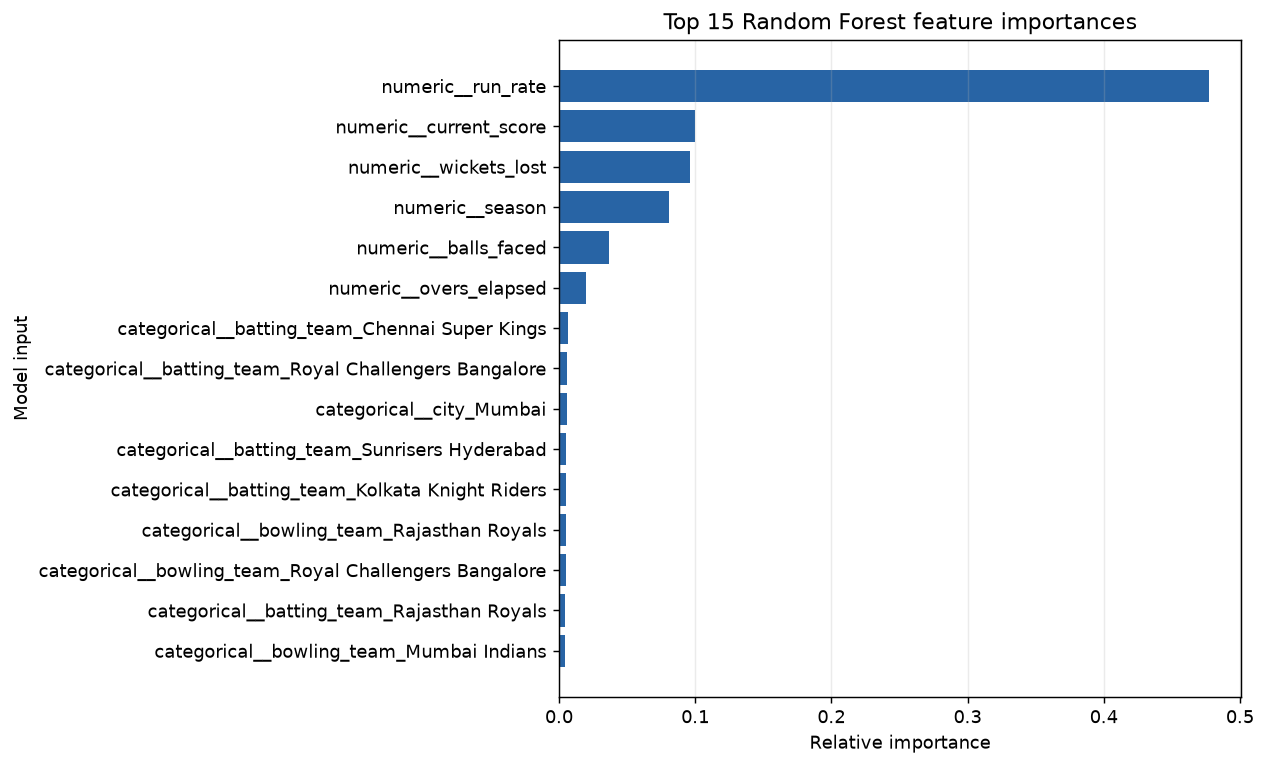

In [5]:
# Model diagnostics: holdout fit, error by over, and late-classifier confusion matrix.
holdout_states = data.iloc[test_idx].copy()
holdout_states['predicted_final_score'] = predictions
holdout_states['absolute_error'] = (holdout_states['final_score'] - holdout_states['predicted_final_score']).abs()
error_by_over = holdout_states.groupby('overs_elapsed')['absolute_error'].mean()
cm = confusion_matrix(late_actual, late_predictions, labels=[0, 1])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(y_test, predictions, color='#2864a5', alpha=0.35, s=15, edgecolors='none')
line_min = min(float(y_test.min()), float(predictions.min()))
line_max = max(float(y_test.max()), float(predictions.max()))
axes[0].plot([line_min, line_max], [line_min, line_max], color='#d1495b', linestyle='--', linewidth=2, label='Perfect estimate')
axes[0].set(title='Actual vs predicted final score', xlabel='Actual score (runs)', ylabel='Predicted score (runs)')
axes[0].legend(frameon=False)

axes[1].plot(error_by_over.index, error_by_over.values, color='#2a8f6a', marker='o', linewidth=2)
axes[1].set(title='Mean absolute error by over', xlabel='Completed overs', ylabel='Mean absolute error (runs)')
axes[1].grid(alpha=0.25)

image = axes[2].imshow(cm, cmap='Blues')
axes[2].set(title='Late classifier: 180+ confusion matrix', xlabel='Predicted class', ylabel='Actual class', xticks=[0, 1], yticks=[0, 1], xticklabels=['Below 180', '180+'], yticklabels=['Below 180', '180+'])
for row in range(2):
    for col in range(2):
        axes[2].text(col, row, f'{cm[row, col]:,}', ha='center', va='center', color='white' if cm[row, col] > cm.max() * 0.55 else '#1d2939', fontsize=12, fontweight='bold')
fig.colorbar(image, ax=axes[2], fraction=0.046, pad=0.04)
fig.suptitle('Held-out model diagnostics', fontsize=15, fontweight='bold')
fig.tight_layout()
fig.savefig(PLOT_DIR / 'model_diagnostics.png', dpi=160, bbox_inches='tight')
plt.show()

# Random Forest feature importances, including one-hot encoded categorical inputs.
feature_names = model.named_steps['preprocess'].get_feature_names_out()
importance = pd.Series(model.named_steps['regressor'].feature_importances_, index=feature_names).nlargest(15).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(importance.index, importance.values, color='#2864a5')
ax.set(title='Top 15 Random Forest feature importances', xlabel='Relative importance', ylabel='Model input')
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
fig.savefig(PLOT_DIR / 'feature_importance.png', dpi=160, bbox_inches='tight')
plt.show()

### High-score classification results (held-out matches)

The regression model's 180+ threshold classification across all over snapshots reached **79.6% accuracy** and **74.1% precision**. The dedicated classifier trained for late innings (after at least 16 overs) reached **89.9% accuracy**, **89.3% precision**, and **78.3% recall** on **852 held-out snapshots**.

The late classifier only applies after 16 completed overs. It predicts whether the final score will reach 180; it does not estimate the final score itself. The score regressor remains available for numerical predictions. DuckDB checks the data and writes compressed Parquet copies; Dask aggregates delivery rows and Polars builds cumulative over-by-over features.

## 5. Review predictions and save the trained model

The held-out predictions below show actual and predicted final totals at different over checkpoints. The saved model expects the same feature fields as the training data.

In [ ]:
results = data.iloc[test_idx][['match_id', 'batting_team', 'overs_elapsed', 'current_score', 'wickets_lost', 'final_score']].copy()
results['predicted_final_score'] = predictions
results['absolute_error'] = (results['final_score'] - results['predicted_final_score']).abs()
display(results.head(15).round(1))

model_path = OUTPUT_DIR / 'first_innings_score_model.joblib'
metrics_path = OUTPUT_DIR / 'metrics.json'
results_path = OUTPUT_DIR / 'holdout_predictions.csv'
late_results_path = OUTPUT_DIR / 'late_classifier_holdout_predictions.csv'
joblib.dump({'pipeline': model, 'feature_columns': feature_columns, 'numeric_features': numeric_features, 'categorical_features': categorical_features, 'late_innings_classifier': late_classifier, 'late_classifier_feature_columns': feature_columns, 'late_classifier_min_overs_elapsed': 16, 'late_classifier_score_threshold': 180}, model_path)
results.to_csv(results_path, index=False)
late_results = late_test[['match_id', 'batting_team', 'overs_elapsed', 'current_score', 'wickets_lost', 'final_score']].copy()
late_results['actual_180_plus'] = late_actual.to_numpy()
late_results['predicted_180_plus'] = late_predictions
late_results.to_csv(late_results_path, index=False)

with mlflow.start_run(run_name='random-forest-score-and-late-classifier') as active_run:
    mlflow.log_params({
        'score_model': 'RandomForestRegressor',
        'score_n_estimators': 25,
        'score_min_samples_leaf': 5,
        'score_max_features': 0.5,
        'score_random_state': 42,
        'late_model': 'LogisticRegression',
        'late_c': 0.5,
        'late_min_overs_elapsed': 16,
        'high_score_cutoff_runs': 180,
        'test_split': '20% grouped by match_id',
        'feature_data': 'Dask over Parquet plus Polars cumulative features',
        'training_samples': len(data),
        'train_matches': metrics['train_matches'],
        'test_matches': metrics['test_matches'],
    })
    mlflow.log_metrics({key: float(metrics[key]) for key in [
        'MAE', 'RMSE', 'R2', 'high_score_accuracy', 'high_score_precision',
        'late_classifier_accuracy', 'late_classifier_precision', 'late_classifier_recall'
    ]})
    mlflow.set_tags({
        'project': 'cricket-score-prediction',
        'data_quality': 'passed' if quality_report['issue_count'].sum() == 0 else 'issues-found',
        'prediction_task': 'first-innings final score and 180-plus classification',
    })
    metrics.update({
        'mlflow_run_id': active_run.info.run_id,
        'mlflow_experiment_id': active_run.info.experiment_id,
        'mlflow_tracking_uri': MLFLOW_TRACKING_URI,
    })
    metrics_path.write_text(json.dumps(metrics, indent=2))
    mlflow.log_artifact(str(model_path), artifact_path='model')
    mlflow.log_artifact(str(metrics_path), artifact_path='evaluation')
    mlflow.log_artifact(str(quality_report_path), artifact_path='data_quality')
    mlflow.log_artifact(str(results_path), artifact_path='predictions')
    mlflow.log_artifact(str(late_results_path), artifact_path='predictions')

print(f'Saved model and evaluation files to {OUTPUT_DIR}')
print(f"MLflow run logged: {active_run.info.run_id}")
print(f'MLflow local tracking store: {MLFLOW_TRACKING_URI}')

## View training runs in MLflow

Each notebook training run logs its parameters, evaluation metrics, data quality report, holdout predictions, and saved model. Run metadata is stored in `mlflow.db`; logged artifacts are stored in `mlartifacts/`. To compare runs, open a terminal at the project root and run:

```powershell
.\datasets\.venv\Scripts\Activate.ps1
python -m mlflow ui --backend-store-uri sqlite:///./mlflow.db --port 5000
```

Then open `http://localhost:5000` in your browser.

## 6. Try a prediction

Enter a first-innings state after a completed over. The team and venue names should resemble values in the datasets; unseen values are supported.

In [ ]:
def predict_final_score(batting_team, bowling_team, venue, city, season, overs_elapsed, current_score, wickets_lost):
    if not 1 <= overs_elapsed < 20:
        raise ValueError('overs_elapsed must be between 1 and 19 for an in-progress first innings.')
    if not 0 <= wickets_lost <= 10 or current_score < 0:
        raise ValueError('Score and wicket count must be non-negative; wickets_lost must be at most 10.')
    row = pd.DataFrame([{'season': season, 'overs_elapsed': overs_elapsed, 'current_score': current_score,
        'wickets_lost': wickets_lost, 'balls_faced': overs_elapsed * 6,
        'run_rate': current_score / overs_elapsed, 'batting_team': batting_team,
        'bowling_team': bowling_team, 'city': city, 'venue': venue}], columns=feature_columns)
    return round(float(max(current_score, model.predict(row)[0])))

# Example only; change these values to the live match state you want to estimate.
predict_final_score('Chennai Super Kings', 'Mumbai Indians', 'M. A. Chidambaram Stadium', 'Chennai', 2024, 10, 82, 3)

## Notes and limitations
- The prediction updates at over breaks and estimates the final score of the first innings.
- Training data comes from historical matches in the supplied files; teams, rules, venues, or scoring patterns may change over time.
- The simple example helper estimates balls faced as six per completed over. The fitted snapshots use the observed delivery counts, which account for wides and no-balls.